# 2 · Diffusion from three regions — corrected

Corrected version of [`original/notebooks/02-diffusion-three-regions.ipynb`](../../original/notebooks/02-diffusion-three-regions.ipynb). The original is kept unchanged.

**Model** — pure diffusion, $\dfrac{\partial n}{\partial t} = D\,\nabla^2 n$, starting from three overlapping Gaussian regions.

**What changed from the original**

- **Runs on its own.** The original loop used `num_step` and `matrix_next`, which this notebook never defines (it defines `num_steps`). It only ran because those variables were left in memory from another notebook, so *Restart & Run All* failed with a `NameError`. This version defines everything it uses.
- **Reaches the last step.** The original looped over `range(num_step)`, which stops at 1999, so the step-2000 snapshot was never drawn.
- **Formula.** The original wrote `D * (delta_t / delta_x)`. That only equals the correct `D * delta_t / delta_x**2` because `delta_x = 1`; it is written correctly here.
- **Speed.** NumPy array operations instead of nested Python loops.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Parameters (same as the original)
l = 200
A = 0.05
σ1, σ2, σ3 = 15, 25, 12
delta_t = 0.1
delta_x = 1
D = 2
num_steps = 2000
save_steps = [100, 480, 860, 1240, 1620, 2000]

# The explicit scheme is only stable if D*dt/dx^2 <= 0.25 (2D, 5-point stencil)
assert D * delta_t / delta_x**2 <= 0.25, "unstable: reduce delta_t"

In [3]:
def laplacian(n):
    """5-point Laplacian. np.roll wraps around the edges, giving the same
    periodic boundaries as the original notebook."""
    return (np.roll(n, 1, axis=0) + np.roll(n, -1, axis=0)
            + np.roll(n, 1, axis=1) + np.roll(n, -1, axis=1) - 4 * n) / delta_x**2

In [4]:
# Same three Gaussian regions as the original notebook
i, j = np.meshgrid(np.arange(l), np.arange(l), indexing="ij")

def gaussian(ci, cj, sigma):
    return A * np.exp(-((i - ci)**2 + (j - cj)**2) / (2 * sigma**2))

n = gaussian(l/2, l/2 - 10, σ1) + gaussian(l/2, 3*l/4 - 30, σ2) + gaussian(2*l/5, 3*l/5 - 10, σ3)
n_initial = n.copy()

In [5]:
frames = {0: n.copy()}
for step in range(1, num_steps + 1):
    n = n + delta_t * D * laplacian(n)
    if step in save_steps:
        frames[step] = n.copy()

print(f"total density: start {n_initial.sum():.6f}, end {n.sum():.6f}")

total density: start 312.117232, end 312.117232


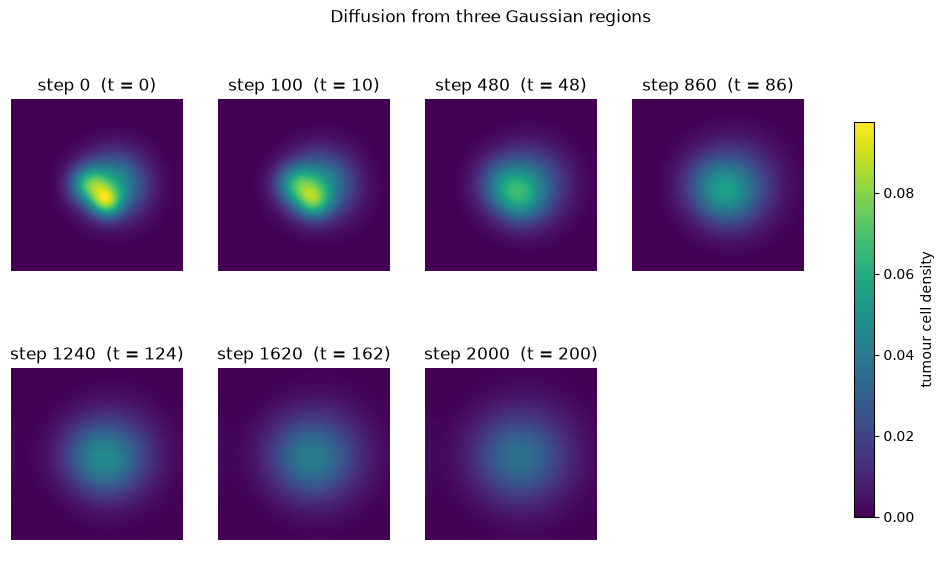

In [6]:
fig, axes = plt.subplots(int(np.ceil(len(frames) / 4)), 4, figsize=(3.2 * 4, 3.2 * int(np.ceil(len(frames) / 4))), squeeze=False)
for ax in axes.flat:
    ax.axis("off")
for ax, (step, frame) in zip(axes.flat, frames.items()):
    im = ax.imshow(frame, origin="lower", cmap="viridis", vmin=0, vmax=n_initial.max())
    ax.set_title(f"step {step}  (t = {step * delta_t:g})")
fig.colorbar(im, ax=axes, shrink=0.8, label="tumour cell density")
fig.suptitle("Diffusion from three Gaussian regions")
plt.show()

**Reading the result.** The three regions merge into one blob that keeps flattening out; the total amount stays constant.